In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from warnings import filterwarnings
filterwarnings('ignore')

In [2]:
df = pd.read_excel(r"C:\Users\deytu\Desktop\study\EXCELR\Assignment\Data and Docs\heart_disease.xlsx",sheet_name = "Heart_disease")
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
0,63,Male,typical angina,145,233,True,lv hypertrophy,150,False,2.3,downsloping,fixed defect,0
1,41,Male,atypical angina,135,203,False,normal,132,False,0.0,flat,fixed defect,0
2,57,Male,asymptomatic,140,192,False,normal,148,False,0.4,flat,fixed defect,0
3,52,Male,typical angina,118,186,False,lv hypertrophy,190,False,0.0,flat,fixed defect,0
4,57,Male,asymptomatic,110,201,False,normal,126,True,1.5,flat,fixed defect,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
903,53,Male,asymptomatic,125,0,False,normal,120,False,1.5,upsloping,normal,4
904,62,Male,asymptomatic,166,170,False,st-t abnormality,120,True,3.0,flat,reversable defect,4
905,56,Male,non-anginal,170,0,False,lv hypertrophy,123,True,2.5,downsloping,reversable defect,4
906,56,Male,non-anginal,144,208,True,st-t abnormality,105,TURE,NaN,downsloping,reversable defect,4


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 908 entries, 0 to 907
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       908 non-null    int64  
 1   sex       908 non-null    object 
 2   cp        908 non-null    object 
 3   trestbps  908 non-null    int64  
 4   chol      908 non-null    int64  
 5   fbs       908 non-null    bool   
 6   restecg   908 non-null    object 
 7   thalch    908 non-null    int64  
 8   exang     908 non-null    object 
 9   oldpeak   846 non-null    float64
 10  slope     908 non-null    object 
 11  thal      908 non-null    object 
 12  num       908 non-null    int64  
dtypes: bool(1), float64(1), int64(5), object(6)
memory usage: 86.1+ KB


In [4]:
df.describe()

,age,trestbps,chol,thalch,oldpeak,num
count,908.000000,908.000000,908.000000,908.000000,846.000000,908.000000
mean,53.791850,133.430617,201.484581,135.957048,0.891253,1.008811
std,9.158031,20.401608,112.097949,26.804929,1.093875,1.144436
min,29.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.750000,120.000000,176.750000,118.000000,0.000000,0.000000
50%,54.000000,130.000000,224.000000,138.000000,0.500000,1.000000
75%,60.000000,144.000000,270.000000,156.000000,1.500000,2.000000
max,77.000000,200.000000,603.000000,202.000000,6.200000,4.000000


In [5]:
columns = ["age","sex","cp","trestbps","chol","fbs","restecg","thalch","exang","oldpeak","slope","thal","num"]
cat_columns = ["sex","cp","fbs","restecg","exang","slope","thal"]
for col in cat_columns:
    print(df[col].value_counts())


sex
Male      718
Female    190
Name: count, dtype: int64
cp
asymptomatic       495
non-anginal        203
atypical angina    165
typical angina      45
Name: count, dtype: int64
fbs
False    723
True     185
Name: count, dtype: int64
restecg
normal              542
lv hypertrophy      187
st-t abnormality    179
Name: count, dtype: int64
exang
False    516
True     337
TURE      36
FALSE     19
Name: count, dtype: int64
slope
flat           453
upsloping      298
downsloping    157
Name: count, dtype: int64
thal
reversable defect    372
normal               339
fixed defect         197
Name: count, dtype: int64


### Observations 
- Null values are present in oldpeak
- in exang few records are mislabeled from True to TURE and False to FALSE

In [6]:
## dropping na values 
df["oldpeak"].isna().value_counts()

oldpeak
False    846
True      62
Name: count, dtype: int64

<Axes: ylabel='oldpeak'>

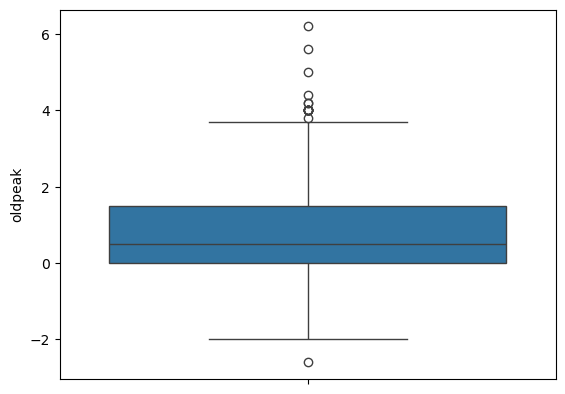

In [7]:
sns.boxplot(df["oldpeak"])

In [8]:
## since outliers are present we will use median 
df["oldpeak"]=df["oldpeak"].fillna(df["oldpeak"].median())


In [9]:
df["oldpeak"].isna().value_counts()

oldpeak
False    908
Name: count, dtype: int64

In [10]:
df["exang"]=df["exang"].replace("TURE",True)
df["exang"] =df["exang"].replace("FALSE",False)
df["exang"] = df["exang"].replace({"True": True, "False": False})

In [11]:
df["exang"].value_counts()

exang
False    535
True     373
Name: count, dtype: int64

In [12]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
0,63,Male,typical angina,145,233,True,lv hypertrophy,150,False,2.3,downsloping,fixed defect,0
1,41,Male,atypical angina,135,203,False,normal,132,False,0.0,flat,fixed defect,0
2,57,Male,asymptomatic,140,192,False,normal,148,False,0.4,flat,fixed defect,0
3,52,Male,typical angina,118,186,False,lv hypertrophy,190,False,0.0,flat,fixed defect,0
4,57,Male,asymptomatic,110,201,False,normal,126,True,1.5,flat,fixed defect,0


###  Observations
---
- The dataset contains 908 patient records with a mix of numerical and categorical features related to heart disease, making it suitable for classification tasks.
- The oldpeak feature contains missing values, which were appropriately handled using median imputation because the variable is skewed and contains - outliers.
- The chol (cholesterol) feature contains zero values, which are medically unrealistic and may represent missing or incorrectly recorded data. These values should be treated during preprocessing.
- The categorical feature exang (exercise-induced angina) initially had inconsistent values (e.g., True, False, TURE, FALSE), but after cleaning, it contains consistent boolean values suitable for analysis and modeling.

In [13]:
df["chol"].value_counts()

chol
0      172
230      9
211      9
223      9
219      9
      ... 
165      1
161      1
139      1
385      1
109      1
Name: count, Length: 228, dtype: int64

In [14]:
df["chol"]= df["chol"].replace(0,np.nan)


In [15]:
print((df["chol"]=="0").sum())

0


<Axes: ylabel='chol'>

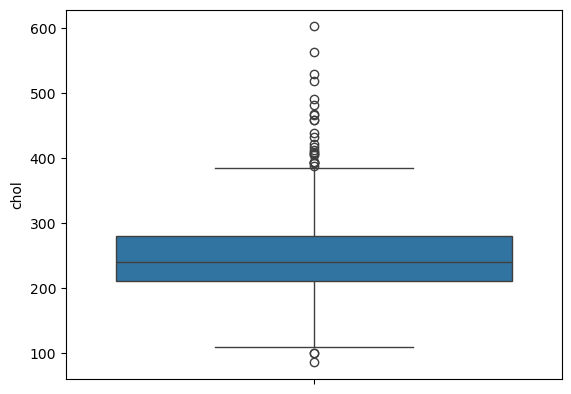

In [16]:
sns.boxplot(df["chol"])

In [17]:
df["chol"] = df["chol"].fillna(df["chol"].median())
df["chol"].isna().value_counts()

chol
False    908
Name: count, dtype: int64

### Visualization

<Axes: >

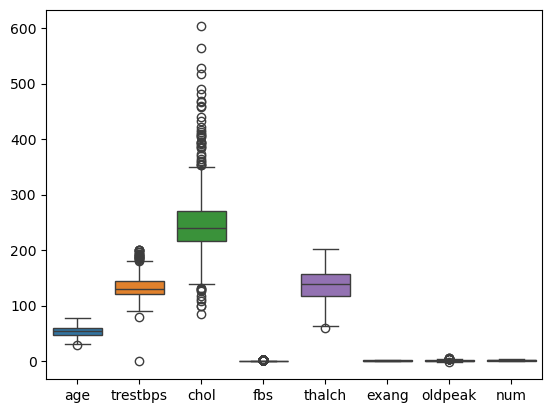

In [18]:
sns.boxplot(df)

In [19]:
df["chol"].value_counts()

chol
240.0    180
216.0      9
219.0      9
211.0      9
254.0      9
        ... 
406.0      1
165.0      1
161.0      1
139.0      1
109.0      1
Name: count, Length: 227, dtype: int64

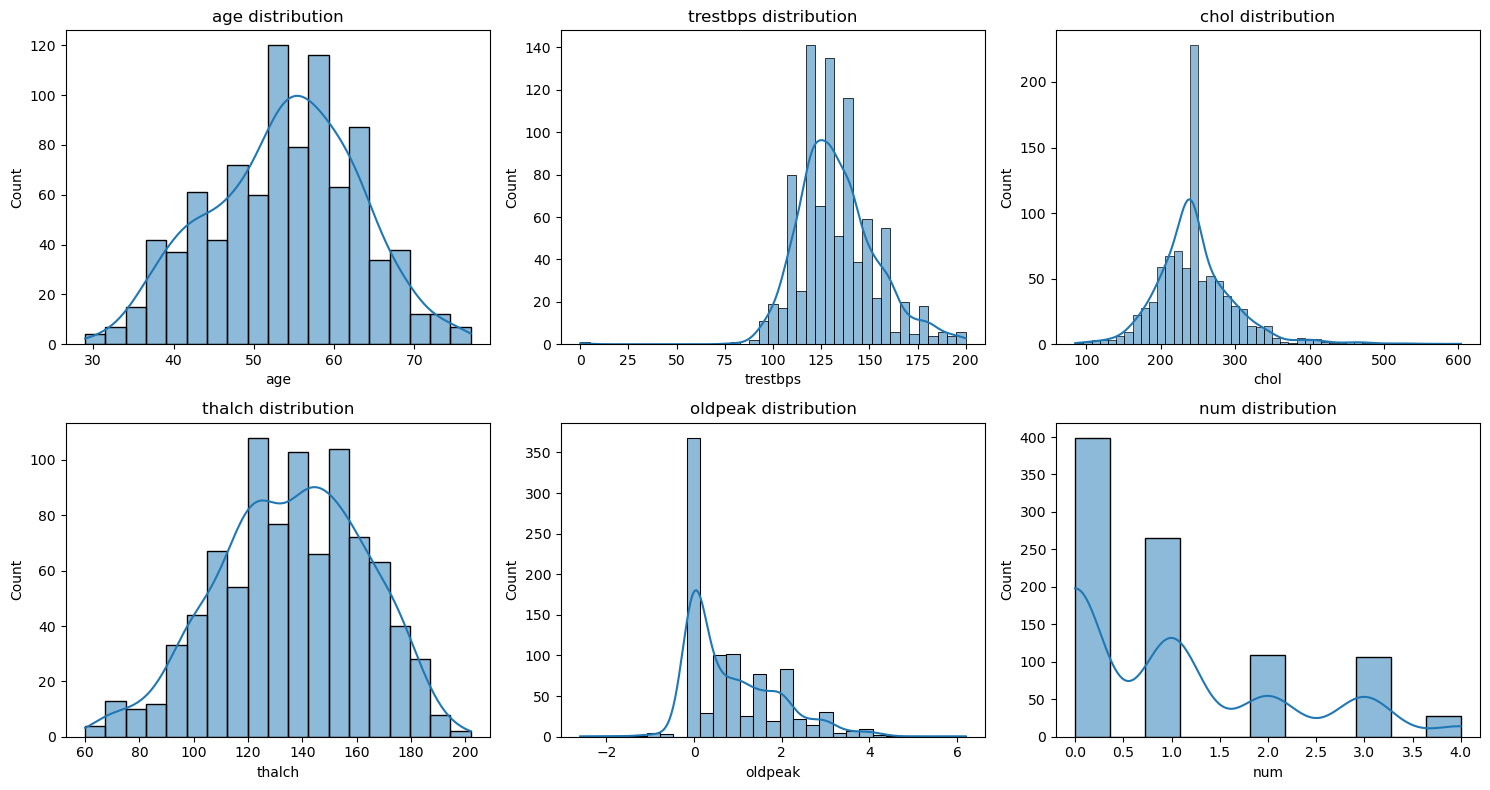

In [20]:
num_cols = ["age",	"trestbps",	"chol",	"thalch",	"oldpeak",	"num"]
fig , axes = plt.subplots(2,3, figsize = (15,8))
axes = axes.flatten()
for i,col in enumerate(num_cols):
    sns.histplot(data = df , x = col , kde = True , ax = axes[i])
    axes[i].set_title(f"{col} distribution")
plt.tight_layout()
plt.show()

In [21]:
df[num_cols].corr()

,age,trestbps,chol,thalch,oldpeak,num
age,1.000000,0.253999,0.017162,-0.328088,0.217942,0.326493
trestbps,0.253999,1.000000,0.108062,-0.133360,0.134945,0.137251
chol,0.017162,0.108062,1.000000,-0.010721,0.007946,0.011257
thalch,-0.328088,-0.133360,-0.010721,1.000000,-0.112624,-0.323058
oldpeak,0.217942,0.134945,0.007946,-0.112624,1.000000,0.406078
num,0.326493,0.137251,0.011257,-0.323058,0.406078,1.000000


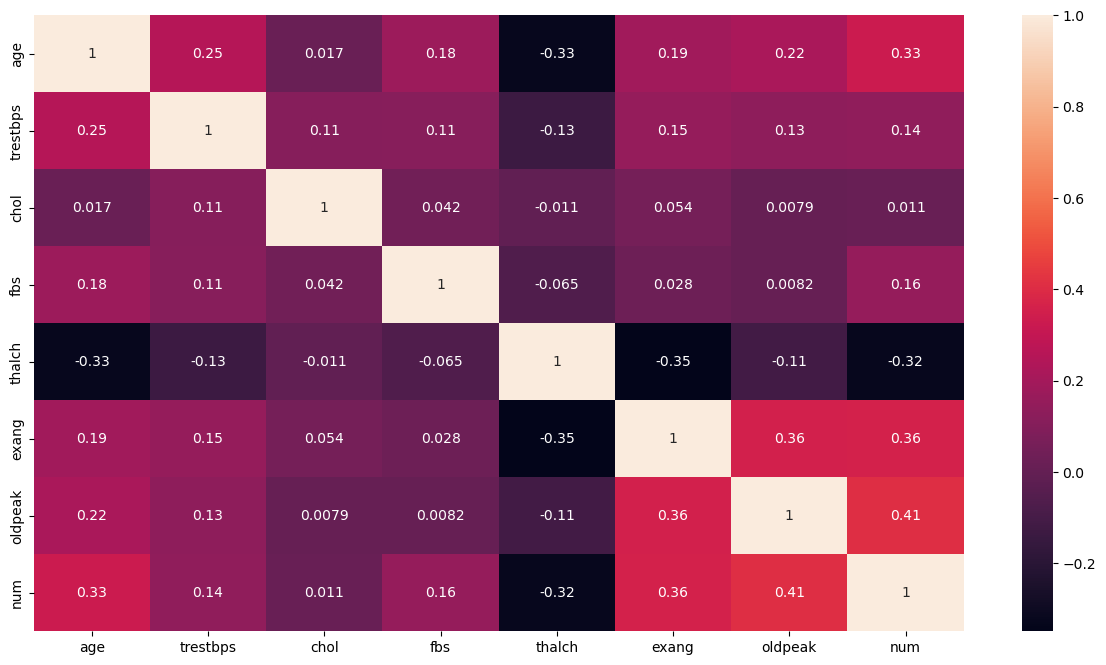

In [22]:
plt.figure(figsize=(15,8))
sns.heatmap(df.corr(numeric_only = True) , annot = True )
plt.show()

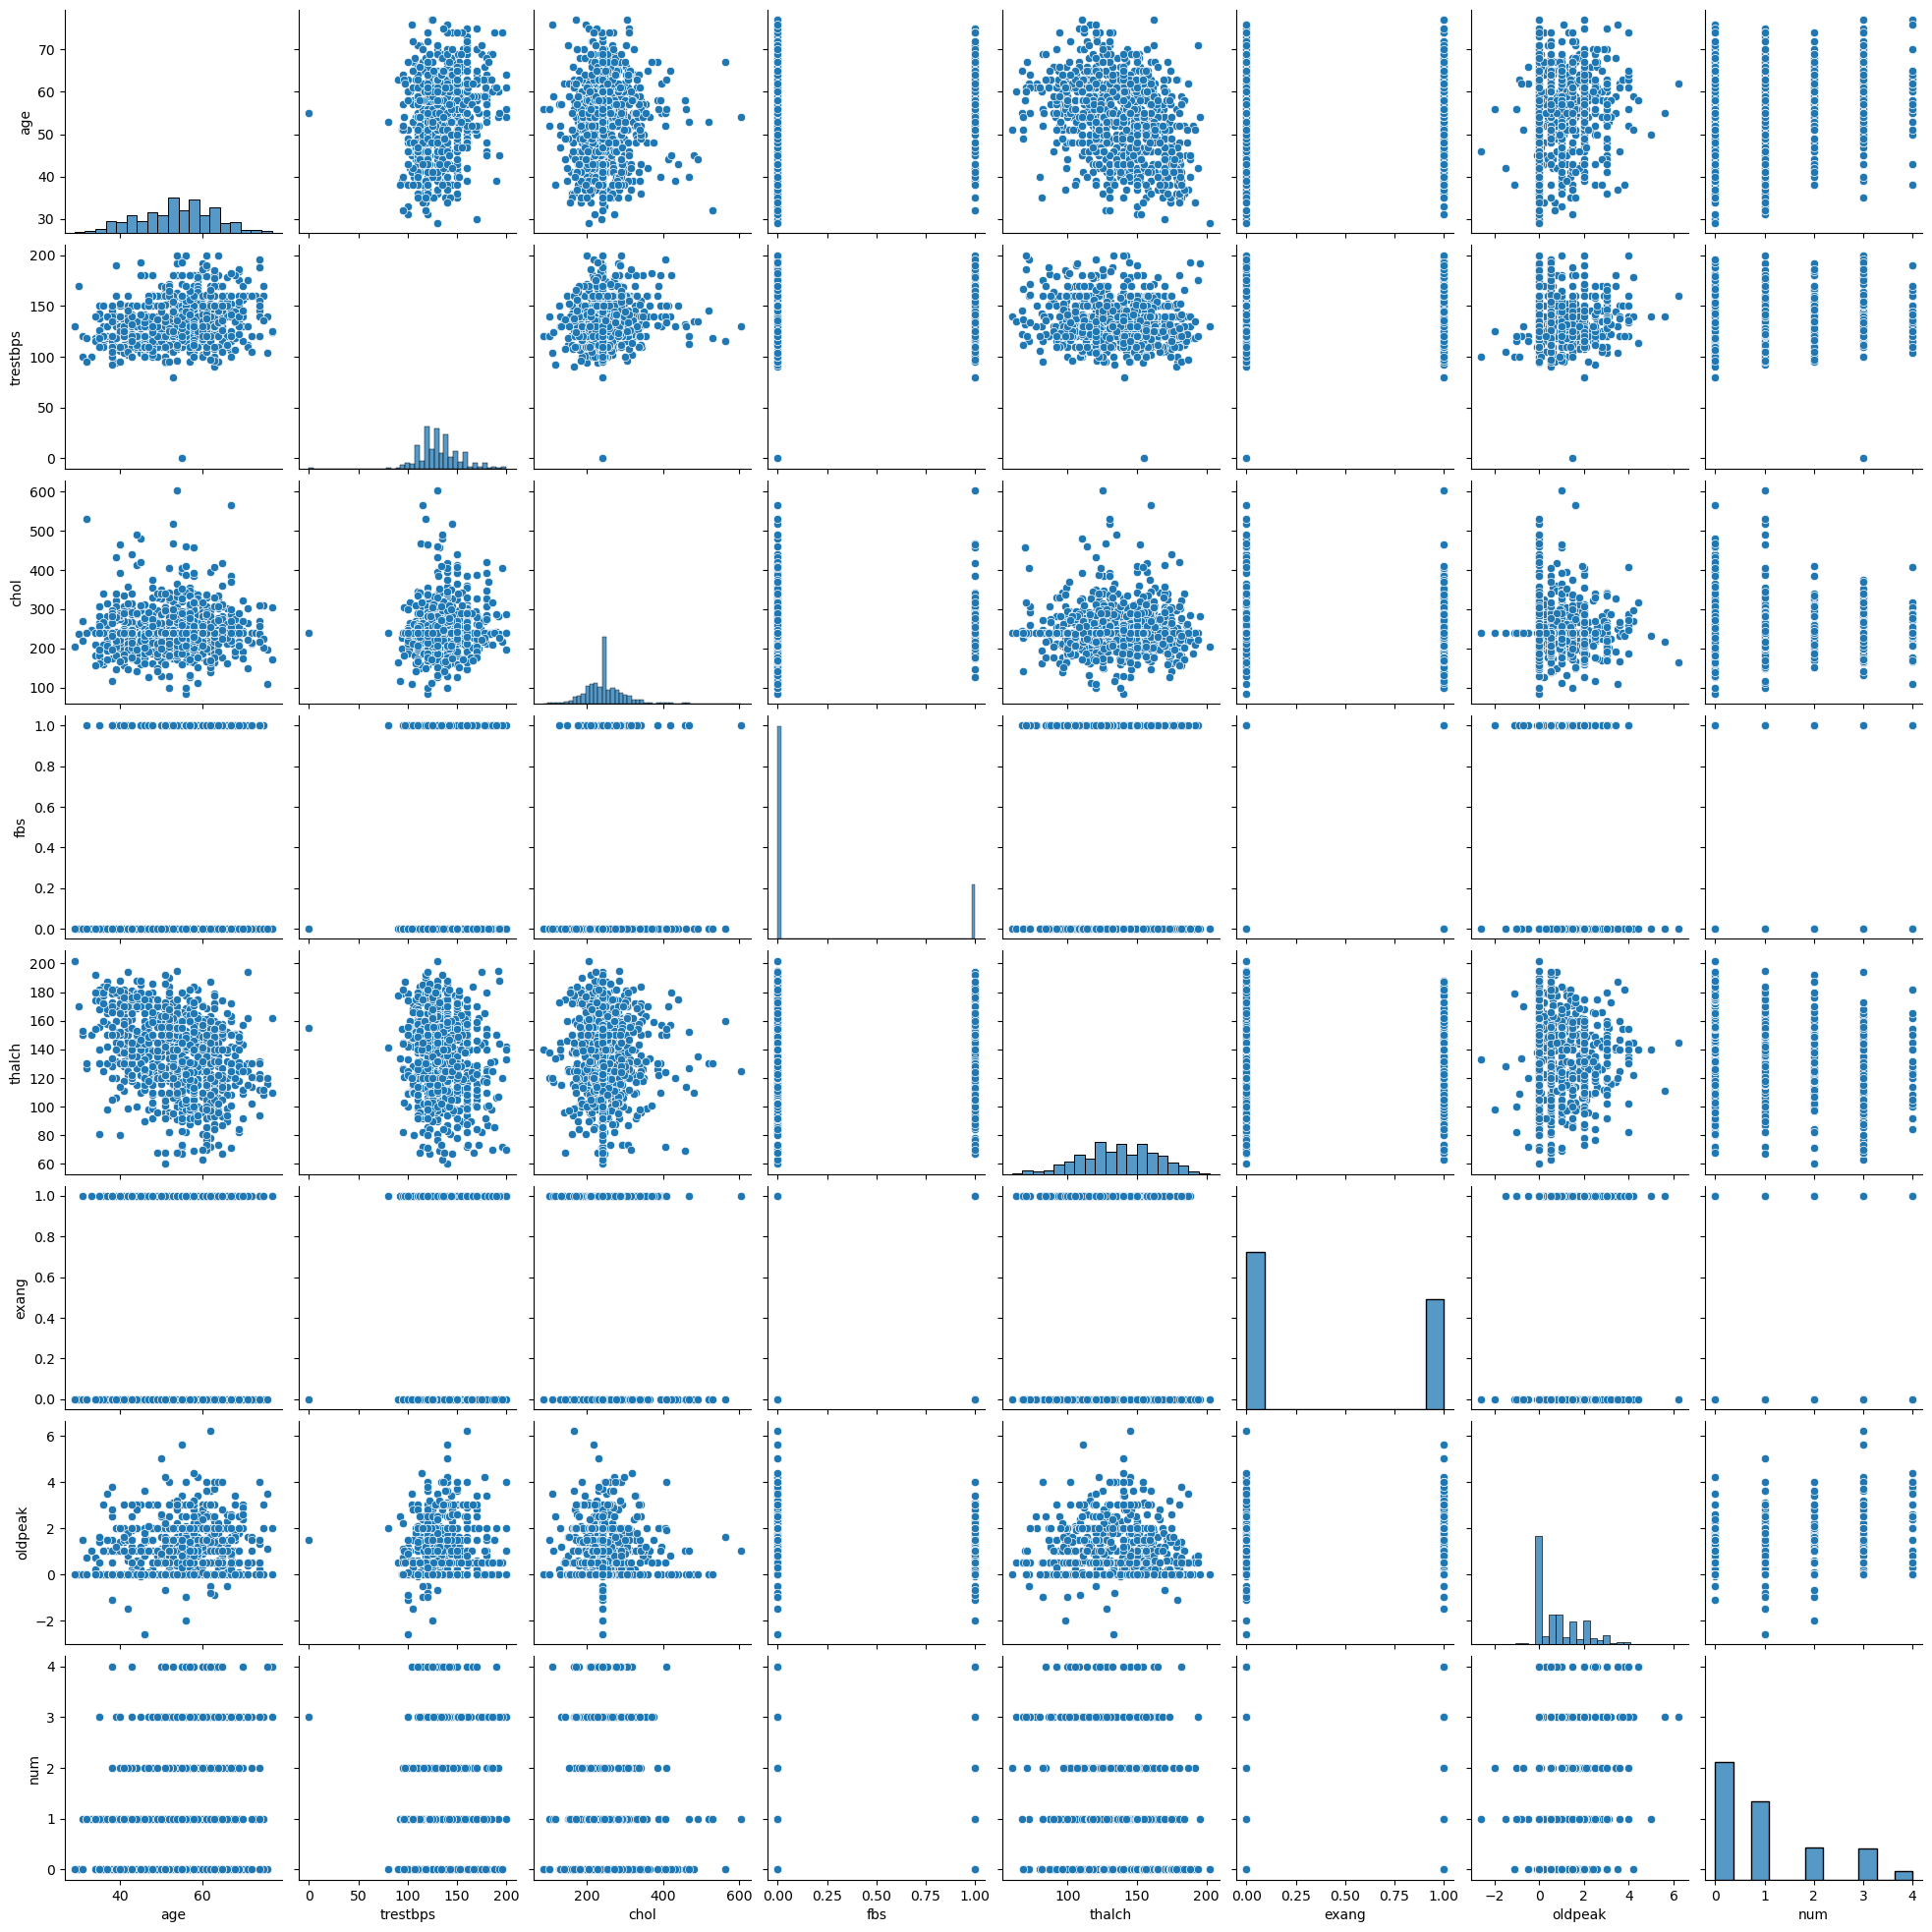

In [23]:
sns.pairplot(df)

### feature scaling 

In [24]:
## one hot encoding 
df_encoded = pd.get_dummies(df, drop_first = True)
df_encoded

,age,trestbps,chol,fbs,thalch,exang,oldpeak,num,sex_Male,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_normal,restecg_st-t abnormality,slope_flat,slope_upsloping,thal_normal,thal_reversable defect
0,63,145,233.0,True,150,False,2.3,0,True,False,False,True,False,False,False,False,False,False
1,41,135,203.0,False,132,False,0.0,0,True,True,False,False,True,False,True,False,False,False
2,57,140,192.0,False,148,False,0.4,0,True,False,False,False,True,False,True,False,False,False
3,52,118,186.0,False,190,False,0.0,0,True,False,False,True,False,False,True,False,False,False
4,57,110,201.0,False,126,True,1.5,0,True,False,False,False,True,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
903,53,125,240.0,False,120,False,1.5,4,True,False,False,False,True,False,False,True,True,False
904,62,166,170.0,False,120,True,3.0,4,True,False,False,False,False,True,True,False,False,True
905,56,170,240.0,False,123,True,2.5,4,True,False,True,False,False,False,False,False,False,True
906,56,144,208.0,True,105,True,0.5,4,True,False,True,False,False,True,False,False,False,True


dataset is now ready for a Decision Tree Classifier. Since num is the target variable (values 0–4), this is a multiclass classification problem.

### Model Training 

In [25]:
### test train split 
from sklearn.model_selection import train_test_split
X = df_encoded.drop("num", axis =1 )
y = df_encoded["num"]
X_train , X_test , y_train , y_test  = train_test_split(X, y , test_size = 0.2 , random_state = 42)

In [26]:
X_train

,age,trestbps,chol,fbs,thalch,exang,oldpeak,sex_Male,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_normal,restecg_st-t abnormality,slope_flat,slope_upsloping,thal_normal,thal_reversable defect
84,42,120,295.0,False,162,False,0.0,True,True,False,False,True,False,False,True,True,False
10,30,170,237.0,False,170,False,0.0,False,False,False,True,False,True,False,False,False,False
617,74,140,237.0,True,94,False,0.0,True,False,True,False,True,False,False,True,False,True
250,41,104,240.0,False,111,False,0.0,True,False,False,False,False,True,True,False,False,True
869,49,137,142.0,False,68,False,0.5,True,False,True,False,True,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,63,135,252.0,False,172,False,0.0,False,False,True,False,False,False,False,True,True,False
270,37,120,260.0,False,130,False,0.0,False,True,False,False,True,False,False,False,True,False
860,48,140,374.0,False,159,True,1.5,True,False,False,False,True,False,False,True,True,False
435,57,154,232.0,False,164,False,0.0,True,True,False,False,False,False,False,True,True,False


In [27]:
### Model 
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state = 42)
dt.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [28]:
## predictions
y_pred = dt.predict(X_test)

In [29]:
## evaluation
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

Accuracy: 0.5

Confusion Matrix
[[63 18  4  3  1]
 [15 19  6  6  2]
 [ 5  8  7  2  0]
 [ 4 10  1  2  0]
 [ 2  3  1  0  0]]

Classification Report
              precision    recall  f1-score   support

           0       0.71      0.71      0.71        89
           1       0.33      0.40      0.36        48
           2       0.37      0.32      0.34        22
           3       0.15      0.12      0.13        17
           4       0.00      0.00      0.00         6

    accuracy                           0.50       182
   macro avg       0.31      0.31      0.31       182
weighted avg       0.49      0.50      0.49       182



- The Decision Tree classifier achieved an overall accuracy of 50%, indicating moderate performance on the multiclass heart disease dataset.
- The model performed best for Class 0, achieving a precision and recall of 71%, while performance on minority classes was considerably lower.
- The poor prediction of Classes 3 and 4 suggests that class imbalance affected the model's ability to learn patterns for less frequent classes.
- Model performance can be improved through hyperparameter tuning, class balancing, or ensemble methods such as Random Forest.

In [30]:
### Hyperparameter tuning 
criteria = ["gini", "entropy"]
max_depths = [3, 5, 7, 10, None]

for criterion in criteria:
    for depth in max_depths:
        dt = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            random_state=42
        )
        dt.fit(X_train, y_train)
        y_pred = dt.predict(X_test)

        acc = accuracy_score(y_test, y_pred)

        print(f"Criterion: {criterion:7} | Max Depth: {str(depth):4} | Accuracy: {acc:.4f}")

Criterion: gini    | Max Depth: 3    | Accuracy: 0.5385
Criterion: gini    | Max Depth: 5    | Accuracy: 0.4835
Criterion: gini    | Max Depth: 7    | Accuracy: 0.5000
Criterion: gini    | Max Depth: 10   | Accuracy: 0.5055
Criterion: gini    | Max Depth: None | Accuracy: 0.5000
Criterion: entropy | Max Depth: 3    | Accuracy: 0.5385
Criterion: entropy | Max Depth: 5    | Accuracy: 0.5220
Criterion: entropy | Max Depth: 7    | Accuracy: 0.5220
Criterion: entropy | Max Depth: 10   | Accuracy: 0.5275
Criterion: entropy | Max Depth: None | Accuracy: 0.5275


entropy is giving us more consistent and higher accuracy score

In [31]:
## Again checking 
best_acc = 0
for criterion in ["gini", "entropy", "log_loss"]:
    for depth in [3, 5, 7, 10, None]:
        for split in [2, 5, 10, 20]:
            for leaf in [1, 2, 5, 10]:
                dt = DecisionTreeClassifier(
                    criterion=criterion,
                    max_depth=depth,
                    min_samples_split=split,
                    min_samples_leaf=leaf,
                    class_weight="balanced",
                    random_state=42
                )

                dt.fit(X_train, y_train)
                acc = dt.score(X_test, y_test)
                if acc > best_acc:
                    best_acc = acc
                    best_model = dt
                    best_params = {
                    "max_depth": depth,
                    "min_samples_split": split,
                    "min_samples_leaf": leaf
                }

print("Best Accuracy:", best_acc)
print("Best Parameters:", best_params)


Best Accuracy: 0.5439560439560439
Best Parameters: {'max_depth': 3, 'min_samples_split': 2, 'min_samples_leaf': 1}


In [32]:
dt = DecisionTreeClassifier(
    class_weight = "balanced",
    criterion="entropy",
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

dt.fit(X_train, y_train)

y_pred = dt.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(acc)

0.5439560439560439


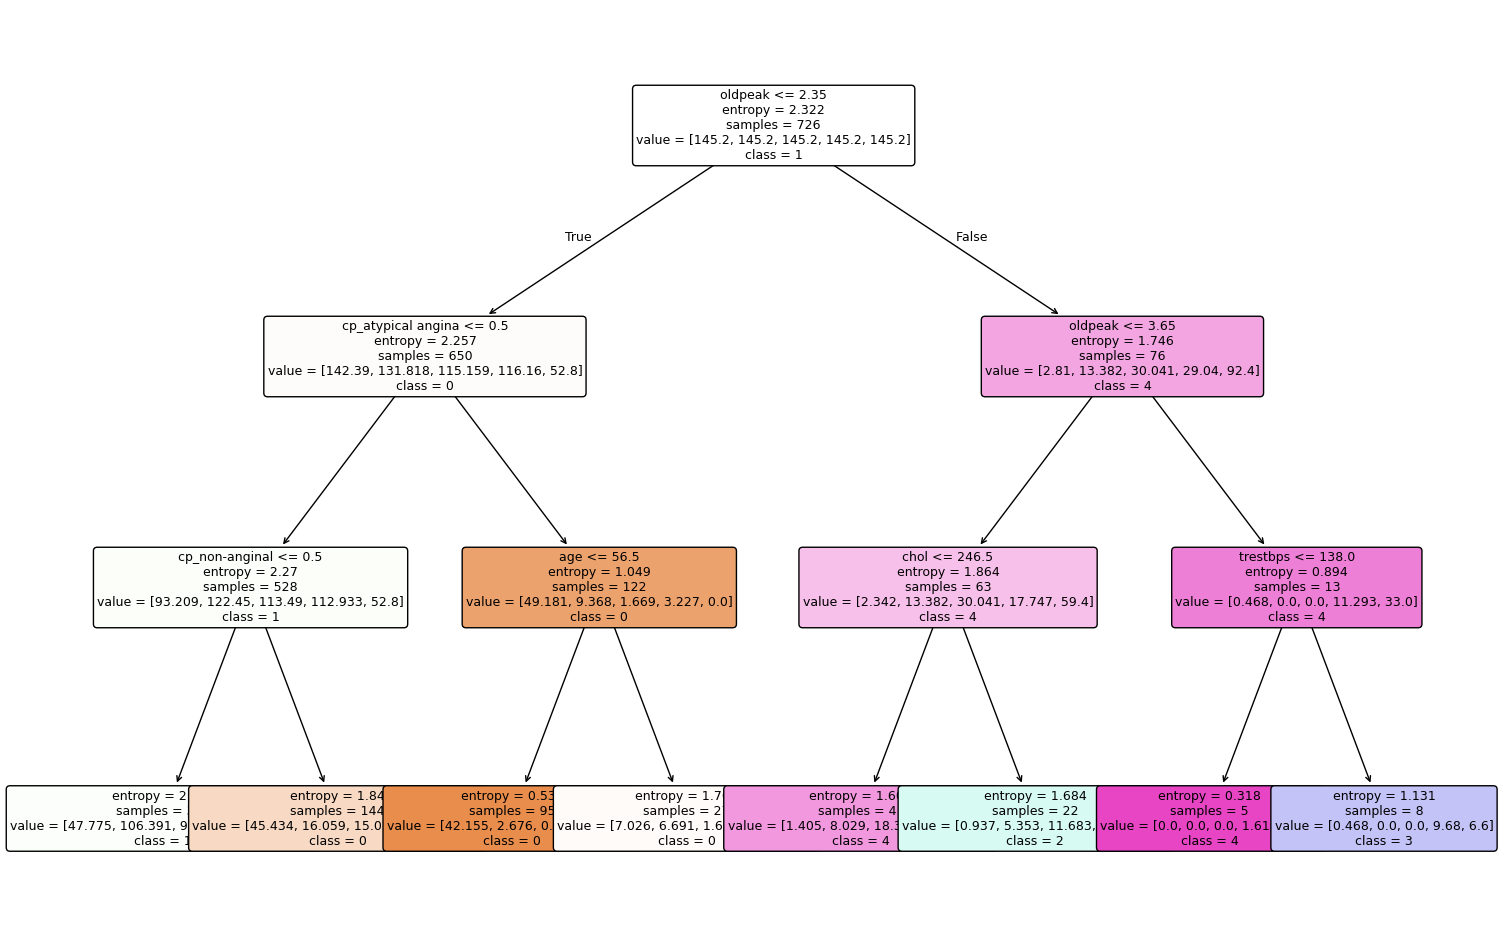

In [33]:
### plotting decision tree
from sklearn.tree import plot_tree
plt.figure(figsize=(18, 12))

plot_tree(
    dt,
    feature_names=X.columns,
    class_names=[str(i) for i in sorted(y.unique())],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.show()

### Observations
- The root node splits on oldpeak ≤ 2.35, indicating that ST depression (`oldpeak`) is the most important feature for predicting heart disease severity.
- For patients with lower oldpeak values (≤ 2.35, the model further splits based on chest pain type (`cp`) and age, suggesting these features are important in distinguishing lower-risk patients.
- For patients with higher oldpeak values (> 2.35, the model relies primarily on cholesterol (`chol and resting blood pressure (`trestbps to classify more severe heart disease cases.
- The shallow tree (maximum depth of 3) is easy to interpret and less prone to overfitting while achieving an accuracy of approximately 54%.

## Interview questions
## 1. What are some common hyperparameters of Decision Tree models, and how do they affect the model's performance?

- max_depth: Controls the maximum depth of the tree. A smaller depth creates a simpler model and reduces overfitting, while a larger depth can improve training accuracy but may overfit the data.
- criterion: Determines how the tree chooses the best split. Common options are gini and entropy, both of which measure the quality of a split.
- min_samples_split: Specifies the minimum number of samples required to split a node. Higher values create a simpler tree and help prevent overfitting.
- min_samples_leaf: Sets the minimum number of samples that must be present in a leaf node. Larger values make the model more stable and less sensitive to noise.
- class_weight: Assigns different weights to classes. Using `class_weight="balanced"` helps improve performance when the dataset has imbalanced classes.

## 2. What is the difference between Label Encoding and One-Hot Encoding?

Label Encoding converts each category into a unique integer. For example, Red = 0, Blue = 1, and Green = 2. It is suitable for ordinal data where the categories have a meaningful order, but it may introduce an unintended ranking for nominal data.

One-Hot Encoding creates a separate binary (0 or 1) column for each category. For example, a "Color" feature with Red, Blue, and Green becomes three columns: `Color_Red`, `Color_Blue`, and `Color_Green`. It is preferred for nominal data because it does not imply any order between categories.